<a href="https://colab.research.google.com/github/nasy-sr/indobert-ruangguru-sentiment/blob/main/02_preliminary_experiment_imbalanced.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Cell 1 - Instalasi Library dan Persiapan Lingkungan

In [ ]:
!pip install transformers[torch] datasets "scikit-learn<1.9" accelerate -U

Cell 2 - Koneksi Google Drive dan Pengambilan Sampel Data

In [ ]:
from google.colab import drive
import pandas as pd
from sklearn.model_selection import train_test_split

drive.mount('/content/drive')

df_classification = pd.read_csv('/content/drive/MyDrive/Seminar_Nasional_2026/Ruangguru_cleaned_for_indobert.csv')
df_classification = df_classification.dropna(subset=['clean_review']).copy()

label_map = {'Negatif': 0, 'Netral': 1, 'Positif': 2}
df_classification['label'] = df_classification['sentiment'].map(label_map)

max_samples = 15000
_, df_sampled = train_test_split(df_classification, test_size=max_samples/len(df_classification), stratify=df_classification['label'], random_state=42)
df_sampled = df_sampled.reset_index(drop=True)

print(f"Data berhasil dimuat! Total sampel: {len(df_sampled)}")

Mounted at /content/drive
Data berhasil dimuat! Total sampel: 15000


Cell 3 - Konfigurasi Tokenizer IndoBERT dan Fungsi Metrik F1-Score

In [ ]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from transformers import AutoTokenizer

model_name = "indobenchmark/indobert-base-p1"
tokenizer = AutoTokenizer.from_pretrained(model_name)

def compute_metrics(pred):
    labels = pred.label_ids
    preds = pred.predictions.argmax(-1)

    precision, recall, f1, _ = precision_recall_fscore_support(labels, preds, average='macro')
    acc = accuracy_score(labels, preds)

    return {
        'accuracy': acc,
        'f1_score': f1,
        'precision': precision,
        'recall': recall
    }

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/1.53k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/229k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Cell 4 - Implementasi Cost-Sensitive Learning dan Eksekusi 10-Fold Cross Validation

In [ ]:
from sklearn.model_selection import StratifiedKFold
from sklearn.utils.class_weight import compute_class_weight
from transformers import AutoModelForSequenceClassification, Trainer, TrainingArguments
from datasets import Dataset
import torch
from torch import nn
import gc
import numpy as np

skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
fold_f1_scores = []
fold_accuracies = []

hf_dataset = Dataset.from_pandas(df_sampled[['clean_review', 'label']])

def tokenize_function(examples):
    return tokenizer(examples["clean_review"], padding="max_length", truncation=True, max_length=64)

tokenized_datasets = hf_dataset.map(tokenize_function, batched=True)

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(df_sampled['label']),
    y=df_sampled['label']
)
weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to('cuda' if torch.cuda.is_available() else 'cpu')

class CustomTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.get("logits")
        loss_fct = nn.CrossEntropyLoss(weight=weights_tensor)
        loss = loss_fct(logits.view(-1, self.model.config.num_labels), labels.view(-1))
        return (loss, outputs) if return_outputs else loss

training_args = TrainingArguments(
    output_dir='./results',
    num_train_epochs=2,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    weight_decay=0.01,
    logging_dir='./logs',
    logging_steps=100,
    save_strategy="no",
    eval_strategy="epoch"
)

# Define id2label and label2id based on your label_map
id2label = {idx: sentiment for sentiment, idx in label_map.items()}
label2id = label_map

for fold, (train_idx, val_idx) in enumerate(skf.split(np.zeros(len(df_sampled)), df_sampled['label'])):
    print(f"\n--- Memulai Fold {fold + 1} ---")

    train_dataset = tokenized_datasets.select(train_idx)
    eval_dataset = tokenized_datasets.select(val_idx)

    model = AutoModelForSequenceClassification.from_pretrained(
        model_name,
        num_labels=3,
        id2label=id2label,
        label2id=label2id
    )

    trainer = CustomTrainer(
        model=model,
        args=training_args,
        train_dataset=train_dataset,
        eval_dataset=eval_dataset,
        compute_metrics=compute_metrics,
    )

    trainer.train()
    eval_results = trainer.evaluate()

    f1 = eval_results['eval_f1_score']
    acc = eval_results['eval_accuracy']
    fold_f1_scores.append(f1)
    fold_accuracies.append(acc)

    print(f"F1-Score Fold {fold + 1}: {f1:.4f}")

    del model, trainer
    torch.cuda.empty_cache()
    gc.collect()

print("\n==============================")
print(f"Rata-rata F1-Score (Cost-Sensitive): {np.mean(fold_f1_scores):.4f}")
print(f"Rata-rata Akurasi: {np.mean(fold_accuracies):.4f}")

Map:   0%|          | 0/15000 [00:00<?, ? examples/s]

[transformers] `logging_dir` is deprecated and will be removed in v5.2. Please set `TENSORBOARD_LOGGING_DIR` instead.



--- Memulai Fold 1 ---


[transformers] You passed `num_labels=3` which is incompatible to the `id2label` map of length `5`.


pytorch_model.bin:   0%|          | 0.00/498M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/498M [00:00<?, ?B/s]

... (64 outputs left out)

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.weight | MISSING | 
classifier.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,F1 Score,Precision,Recall
1,0.769517,0.829169,0.879333,0.613730,0.602121,0.626968
2,0.678797,0.934789,0.870000,0.583570,0.570999,0.598813


Training Loss,Validation Loss,Epoch,Accuracy,F1 Score,Precision,Recall
0.678797,0.934789,2,0.870000,0.583570,0.570999,0.598813


F1-Score Fold 10: 0.5836

Rata-rata F1-Score (Cost-Sensitive): 0.5897
Rata-rata Akurasi: 0.8669


Cell 5 - Ekstraksi Distribusi Kelas dan Nilai Bobot

In [ ]:
print("--- JUMLAH DATA PER KELAS ---")
print(df_sampled['sentiment'].value_counts())

print("\n--- NILAI BOBOT (WEIGHT) PER KELAS ---")
for sentiment, label_id in label_map.items():
    bobot = class_weights[label_id]
    print(f"Kelas {sentiment}: {bobot:.4f}")

--- JUMLAH DATA PER KELAS ---
sentiment
Positif    12772
Negatif     1672
Netral       556
Name: count, dtype: int64

--- NILAI BOBOT (WEIGHT) PER KELAS ---
Kelas Negatif: 2.9904
Kelas Netral: 8.9928
Kelas Positif: 0.3915


Cell 6 - Visualisasi Confusion Matrix

Menyiapkan pemisahan data 80% Train dan 20% Test...


Map:   0%|          | 0/12000 [00:00<?, ? examples/s]

Map:   0%|          | 0/3000 [00:00<?, ? examples/s]

[transformers] You passed `num_labels=3` which is incompatible to the `id2label` map of length `5`.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.weight | MISSING | 
classifier.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Melatih model final untuk Confusion Matrix (estimasi 5 menit)...


Epoch,Training Loss,Validation Loss,Accuracy,F1 Score,Precision,Recall
1,0.870595,0.778746,0.826333,0.570639,0.537494,0.645731
2,0.595935,0.807175,0.865667,0.619840,0.596278,0.664424


Membuat prediksi pada data Test...


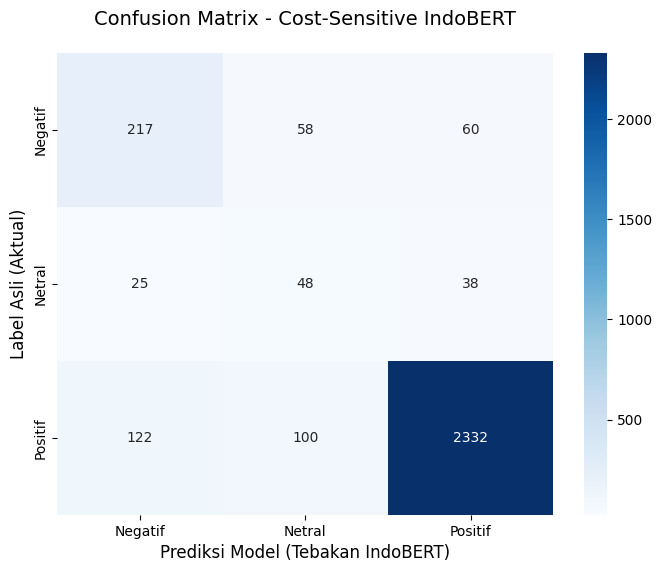


--- Laporan Klasifikasi Detail ---
              precision    recall  f1-score   support

     Negatif       0.60      0.65      0.62       335
      Netral       0.23      0.43      0.30       111
     Positif       0.96      0.91      0.94      2554

    accuracy                           0.87      3000
   macro avg       0.60      0.66      0.62      3000
weighted avg       0.89      0.87      0.88      3000



In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.model_selection import train_test_split
from transformers import AutoModelForSequenceClassification
from datasets import Dataset
import numpy as np

print("Menyiapkan pemisahan data 80% Train dan 20% Test...")
# 1. Split data (80:20)
train_df, test_df = train_test_split(df_sampled, test_size=0.2, stratify=df_sampled['label'], random_state=42)

# 2. Buat dataset Hugging Face
train_hf = Dataset.from_pandas(train_df[['clean_review', 'label']])
test_hf = Dataset.from_pandas(test_df[['clean_review', 'label']])

# 3. Tokenisasi
train_tokenized = train_hf.map(tokenize_function, batched=True)
test_tokenized = test_hf.map(tokenize_function, batched=True)

# 4. Panggil arsitektur model baru
model_final = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=3)

# 5. Gunakan CustomTrainer (Cost-Sensitive) yang sama dengan sebelumnya
trainer_final = CustomTrainer(
    model=model_final,
    args=training_args,
    train_dataset=train_tokenized,
    eval_dataset=test_tokenized,
    compute_metrics=compute_metrics,
)

print("Melatih model final untuk Confusion Matrix (estimasi 5 menit)...")
trainer_final.train()

print("Membuat prediksi pada data Test...")
predictions = trainer_final.predict(test_tokenized)
y_pred = predictions.predictions.argmax(-1)
y_true = predictions.label_ids

# 6. Hitung dan Gambar Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Negatif', 'Netral', 'Positif'],
            yticklabels=['Negatif', 'Netral', 'Positif'])
plt.title('Confusion Matrix - Cost-Sensitive IndoBERT', pad=20, fontsize=14)
plt.xlabel('Prediksi Model (Tebakan IndoBERT)', fontsize=12)
plt.ylabel('Label Asli (Aktual)', fontsize=12)
plt.show()

# 7. Tampilkan Laporan Rinci
print("\n--- Laporan Klasifikasi Detail ---")
print(classification_report(y_true, y_pred, target_names=['Negatif', 'Netral', 'Positif']))

Cell 7 - Menyimpan Model ke Google Drive

In [ ]:
import os

print("Menyimpan model final ke Google Drive...")
output_dir = '/content/drive/MyDrive/Seminar_Nasional_2026/Model_IndoBERT_Ruangguru_CostSensitive'

# Membuat folder jika belum ada
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

# Menyimpan arsitektur model, bobot, dan konfigurasi
trainer_final.save_model(output_dir)

# Menyimpan tokenizer agar cara pemotongan kata tidak berubah
tokenizer.save_pretrained(output_dir)

print(f"Model berhasil disimpan dengan aman di: {output_dir}")

Menyimpan model final ke Google Drive...


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model berhasil disimpan dengan aman di: /content/drive/MyDrive/Seminar_Nasional_2026/Model_IndoBERT_Ruangguru_CostSensitive


Cell 8 - Simulasi Prediksi (Live Testing)

In [ ]:
import torch
import torch.nn.functional as F

def tebak_sentimen(teks_ulasan):
    # 1. Ubah teks menjadi format angka (token)
    inputs = tokenizer(teks_ulasan, padding="max_length", truncation=True, max_length=64, return_tensors="pt")

    # Pindahkan ke GPU jika tersedia
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    inputs = {k: v.to(device) for k, v in inputs.items()}
    model_final.to(device)
    model_final.eval()

    # 2. Lakukan prediksi
    with torch.no_grad():
        outputs = model_final(**inputs)
        logits = outputs.logits

    # 3. Hitung probabilitas persentase keyakinan model
    probabilities = F.softmax(logits, dim=1).squeeze().tolist()

    # 4. Tentukan pemenang
    pred_idx = np.argmax(probabilities)
    kebalikan_label_map = {0: 'Negatif', 1: 'Netral', 2: 'Positif'}
    hasil_sentimen = kebalikan_label_map[pred_idx]

    print(f"Ulasan: '{teks_ulasan}'")
    print(f"Tebakan Model: {hasil_sentimen} (Keyakinan: {probabilities[pred_idx] * 100:.2f}%)")
    print("-" * 30)

# Mari kita tes dengan beberapa kalimat simulasi!
print("--- HASIL UJI COBA LIVE ---")
tebak_sentimen("Aplikasi ini sangat membantu anak saya belajar matematika, tutornya ramah.")
tebak_sentimen("Sering error kalau mau putar video materi, padahal kuota banyak. Tolong perbaiki.")
tebak_sentimen("Tampilannya sudah diupdate kemarin malam.")

--- HASIL UJI COBA LIVE ---
Ulasan: 'Aplikasi ini sangat membantu anak saya belajar matematika, tutornya ramah.'
Tebakan Model: Positif (Keyakinan: 95.10%)
------------------------------
Ulasan: 'Sering error kalau mau putar video materi, padahal kuota banyak. Tolong perbaiki.'
Tebakan Model: Negatif (Keyakinan: 55.72%)
------------------------------
Ulasan: 'Tampilannya sudah diupdate kemarin malam.'
Tebakan Model: Positif (Keyakinan: 51.23%)
------------------------------
